<a href="https://colab.research.google.com/github/asnapareeth004-hue/encoder_decoder/blob/main/Transformer_with_Attention_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Transformer with Attention in PyTorch**


In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device)

Using cpu


## 1. Scaled dot-product attention

$$\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

In [ ]:
def scaled_dot_product_attention(q, k, v, mask=None, dropout=None):
    # q, k, v: (B, H, T, d_k)
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)      # (B, H, Tq, Tk)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    attn = F.softmax(scores, dim=-1)
    if dropout is not None:
        attn = dropout(attn)
    return attn @ v, attn

## 2. Multi-head attention

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.h = num_heads
        self.d_k = d_model // num_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.attn = None  # saved so we can plot it later

    def _split(self, x):
        B, T, _ = x.shape
        return x.view(B, T, self.h, self.d_k).transpose(1, 2)   # (B, H, T, d_k)

    def forward(self, query, key, value, mask=None):
        q = self._split(self.w_q(query))
        k = self._split(self.w_k(key))
        v = self._split(self.w_v(value))
        out, self.attn = scaled_dot_product_attention(q, k, v, mask, self.dropout)
        B, _, T, _ = out.shape
        out = out.transpose(1, 2).contiguous().view(B, T, self.h * self.d_k)
        return self.w_o(out)

## 3. Positional encoding and feed-forward

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return self.dropout(x + self.pe[:, : x.size(1)])


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(d_ff, d_model),
        )

    def forward(self, x):
        return self.net(x)

## 4. Encoder and decoder layers

In [ ]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, src_mask):
        x = self.norm1(x + self.drop(self.self_attn(x, x, x, src_mask)))
        return self.norm2(x + self.drop(self.ff(x)))


class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.norm1, self.norm2, self.norm3 = (nn.LayerNorm(d_model) for _ in range(3))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, src_mask, tgt_mask):
        x = self.norm1(x + self.drop(self.self_attn(x, x, x, tgt_mask)))
        x = self.norm2(x + self.drop(self.cross_attn(x, memory, memory, src_mask)))
        return self.norm3(x + self.drop(self.ff(x)))

## 5. The full Transformer

In [ ]:
class Transformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=512, num_heads=8,
                 num_layers=6, d_ff=2048, dropout=0.1, max_len=5000, pad_idx=0):
        super().__init__()
        self.d_model, self.pad_idx = d_model, pad_idx
        self.src_embed = nn.Embedding(src_vocab, d_model, padding_idx=pad_idx)
        self.tgt_embed = nn.Embedding(tgt_vocab, d_model, padding_idx=pad_idx)
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        self.encoder = nn.ModuleList([EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.decoder = nn.ModuleList([DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.out_proj = nn.Linear(d_model, tgt_vocab)
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def make_src_mask(self, src):
        return (src != self.pad_idx).unsqueeze(1).unsqueeze(2)            # (B,1,1,Ts)

    def make_tgt_mask(self, tgt):
        T = tgt.size(1)
        pad = (tgt != self.pad_idx).unsqueeze(1).unsqueeze(2)             # (B,1,1,Tt)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt.device))
        return pad & causal                                               # (B,1,Tt,Tt)

    def encode(self, src, src_mask):
        x = self.pos_enc(self.src_embed(src) * math.sqrt(self.d_model))
        for layer in self.encoder:
            x = layer(x, src_mask)
        return x

    def decode(self, tgt, memory, src_mask, tgt_mask):
        x = self.pos_enc(self.tgt_embed(tgt) * math.sqrt(self.d_model))
        for layer in self.decoder:
            x = layer(x, memory, src_mask, tgt_mask)
        return x

    def forward(self, src, tgt):
        src_mask, tgt_mask = self.make_src_mask(src), self.make_tgt_mask(tgt)
        memory = self.encode(src, src_mask)
        return self.out_proj(self.decode(tgt, memory, src_mask, tgt_mask))

    @torch.no_grad()
    def greedy_decode(self, src, bos_idx, eos_idx, max_len=50):
        self.eval()
        src_mask = self.make_src_mask(src)
        memory = self.encode(src, src_mask)
        ys = torch.full((src.size(0), 1), bos_idx, dtype=torch.long, device=src.device)
        for _ in range(max_len - 1):
            out = self.decode(ys, memory, src_mask, self.make_tgt_mask(ys))
            next_tok = self.out_proj(out[:, -1]).argmax(-1, keepdim=True)
            ys = torch.cat([ys, next_tok], dim=1)
            if (next_tok == eos_idx).all():
                break
        return ys

## 6. Reverse a sequence

In [ ]:
PAD, BOS, EOS = 0, 1, 2
VOCAB, SEQ, BATCH = 20, 10, 128

def make_batch():
    data = torch.randint(3, VOCAB, (BATCH, SEQ), device=device)
    rev = data.flip(1)
    bos = torch.full((BATCH, 1), BOS, device=device)
    eos = torch.full((BATCH, 1), EOS, device=device)
    src = data
    tgt_in = torch.cat([bos, rev], dim=1)     # decoder input  (shifted right)
    tgt_out = torch.cat([rev, eos], dim=1)    # expected output
    return src, tgt_in, tgt_out

model = Transformer(VOCAB, VOCAB, d_model=128, num_heads=4, num_layers=2,
                    d_ff=256, dropout=0.1, pad_idx=PAD).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

670,228 parameters


## 7. Train

step  100 | loss 1.0241
step  200 | loss 0.2754
step  300 | loss 0.0919
step  400 | loss 0.0749
step  500 | loss 0.0609
step  600 | loss 0.0314
step  700 | loss 0.0342
step  800 | loss 0.0363
step  900 | loss 0.0379
step 1000 | loss 0.0128
step 1100 | loss 0.0224
step 1200 | loss 0.0169
step 1300 | loss 0.0187
step 1400 | loss 0.0152
step 1500 | loss 0.0199


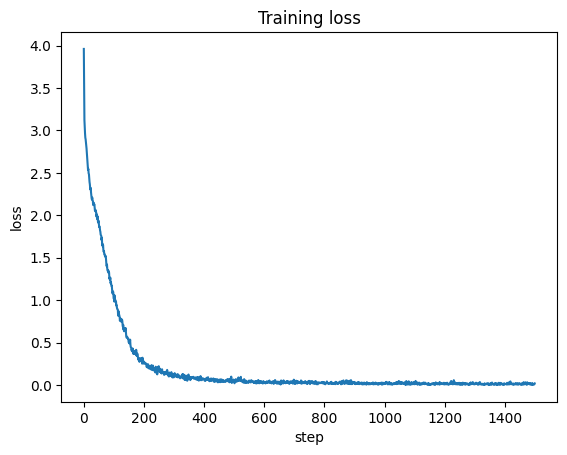

In [ ]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.98), eps=1e-9)
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD)
losses = []

for step in range(1, 1501):
    model.train()
    src, tgt_in, tgt_out = make_batch()
    logits = model(src, tgt_in)
    loss = loss_fn(logits.reshape(-1, VOCAB), tgt_out.reshape(-1))
    opt.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    losses.append(loss.item())
    if step % 100 == 0:
        print(f"step {step:4d} | loss {loss.item():.4f}")

plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss"); plt.show()

## 8. Test

In [ ]:
model.eval()
src, _, _ = make_batch()
pred = model.greedy_decode(src[:5], BOS, EOS, max_len=SEQ + 2)

for i in range(5):
    print("src      :", src[i].tolist())
    print("expected :", src[i].flip(0).tolist())
    print("predicted:", pred[i, 1:].tolist(), "\n")

# exact-match accuracy on a fresh batch
pred_all = model.greedy_decode(src, BOS, EOS, max_len=SEQ + 2)[:, 1:SEQ + 1]
acc = (pred_all == src.flip(1)).all(dim=1).float().mean().item()
print(f"Exact-match accuracy: {acc:.1%}")

src      : [11, 15, 5, 11, 13, 9, 4, 9, 9, 3]
expected : [3, 9, 9, 4, 9, 13, 11, 5, 15, 11]
predicted: [3, 9, 9, 4, 9, 13, 11, 5, 15, 11, 2] 

src      : [10, 11, 6, 3, 4, 11, 4, 13, 10, 16]
expected : [16, 10, 13, 4, 11, 4, 3, 6, 11, 10]
predicted: [16, 10, 13, 4, 11, 4, 3, 6, 11, 10, 2] 

src      : [17, 4, 16, 19, 5, 18, 14, 10, 19, 14]
expected : [14, 19, 10, 14, 18, 5, 19, 16, 4, 17]
predicted: [14, 19, 10, 14, 18, 5, 19, 16, 4, 17, 2] 

src      : [9, 13, 11, 8, 15, 8, 3, 10, 8, 10]
expected : [10, 8, 10, 3, 8, 15, 8, 11, 13, 9]
predicted: [10, 8, 10, 3, 8, 15, 8, 11, 13, 9, 2] 

src      : [16, 14, 3, 11, 5, 16, 7, 3, 8, 18]
expected : [18, 8, 3, 7, 16, 5, 11, 3, 14, 16]
predicted: [18, 8, 3, 7, 16, 5, 11, 3, 14, 16, 2] 

Exact-match accuracy: 100.0%


## 9. Visualize the attention

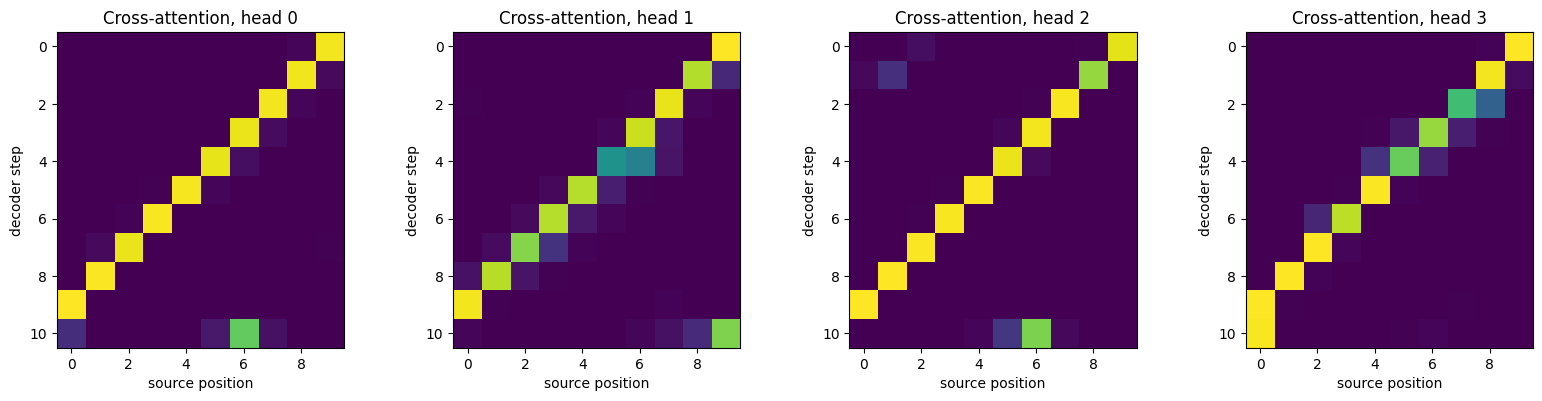

In [ ]:
model.eval()
with torch.no_grad():
    src, tgt_in, _ = make_batch()
    model(src[:1], tgt_in[:1])                       # forward pass fills .attn

attn = model.decoder[-1].cross_attn.attn[0]          # (heads, Tt, Ts)
n_heads = attn.size(0)

fig, axes = plt.subplots(1, n_heads, figsize=(4 * n_heads, 4))
for h, ax in enumerate(axes):
    ax.imshow(attn[h].cpu(), cmap="viridis")
    ax.set_title(f"Cross-attention, head {h}")
    ax.set_xlabel("source position")
    ax.set_ylabel("decoder step")
plt.tight_layout()
plt.show()